# 03 — Yield prediction, economics and rainfall scenarios

## Goal
Predict a continuous yield, convert it into total production, and calculate sample economics with explicit
assumptions. Learn regression metrics and why information leakage can invalidate an apparently strong result.

## Data dictionary
| Column | Meaning |
|---|---|
| Crop, Season, State, Irrigation_Type | Categorical context |
| Area_ha | Area in hectares |
| Rainfall_mm | Reference rainfall input; period is not documented |
| Temperature_c | Temperature in °C |
| Fertilizer_kg_ha | Fertilizer input in kg/ha |
| Yield_tons_per_ha | Target: yield per unit area |
| Production_tons | Derived output: yield × area; excluded from features |

The source generates yield using a crop baseline, rainfall/fertilizer/irrigation factors and noise.
Season, state and temperature are present as inputs but do not enter that generation formula.
A model trained here cannot demonstrate genuine effects of those variables.

## Environment and imports

**What we do:** Locate the project and import the libraries used in this notebook.

**Why we do it:** Relative paths let this project work after it is moved or cloned. pandas handles tables, NumPy handles arrays, and Matplotlib draws graphs. The src package contains shared, readable code.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project folder or its notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import SPECS, load_data
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Project:", ROOT.name)

Project: agrisense-college-mini


**Read the output:** The printed folder should be agrisense-college-mini. In VS Code select the project's .venv Python environment as the notebook kernel. Run cells from top to bottom.

## Load and inspect data

**What we do:** Read the CSV, preview its rows, check column types and summarize numerical values.

**Why we do it:** Inspecting real file contents avoids guessing the schema. load_data also rejects missing values, duplicate rows and non-finite numerical values instead of silently changing them.

In [2]:
KIND = "yield"
df = load_data(KIND)
spec = SPECS[KIND]
display(df.head())
display(df.dtypes.to_frame("Data type"))
display(df.describe().round(2))
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

,Crop,Season,State,Irrigation_Type,Area_ha,Rainfall_mm,Temperature_c,Fertilizer_kg_ha,Yield_tons_per_ha,Production_tons
0,Sugarcane,Zaid,Tamil Nadu,Drip,35.28,1188.1,29.7,220.9,96.34,3398.88
1,Potato,Kharif,Gujarat,Sprinkler,45.24,1473.8,33.9,214.0,22.85,1033.73
2,Sugarcane,Rabi,Punjab,Sprinkler,7.58,233.0,17.5,233.9,74.38,563.80
3,Cotton,Zaid,Haryana,Sprinkler,7.96,1438.3,22.1,189.8,2.40,19.10
4,Maize,Whole Year,Maharashtra,Sprinkler,21.36,534.5,35.0,177.2,4.34,92.70


,Data type
Crop,str
Season,str
State,str
Irrigation_Type,str
Area_ha,float64
Rainfall_mm,float64
Temperature_c,float64
Fertilizer_kg_ha,float64
Yield_tons_per_ha,float64
Production_tons,float64


,Area_ha,Rainfall_mm,Temperature_c,Fertilizer_kg_ha,Yield_tons_per_ha,Production_tons
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,25.41,891.50,25.49,149.71,15.44,402.56
std,14.16,405.06,6.15,58.13,23.76,754.19
min,1.00,200.50,15.00,50.00,0.94,1.71
25%,13.55,539.95,20.10,98.57,2.28,44.78
50%,25.36,891.20,25.50,150.00,3.28,92.07
75%,37.87,1242.45,30.90,199.52,22.08,384.24
max,49.99,1598.10,36.00,250.00,123.58,5059.37


Shape: (2500, 10)
Missing values: 0
Duplicate rows: 0


**Read the output:** Check that the printed columns match the data dictionary. If missing values or duplicates are introduced later, inspect their cause and document a cleaning strategy before training.

## Inspect yield scale and prevent leakage

**What we do:** Plot mean yield by crop and show how production is derived from the target.

**Why we do it:** Different crops have very different yield scales. Including Production_tons would expose information derived from the answer, creating target leakage.

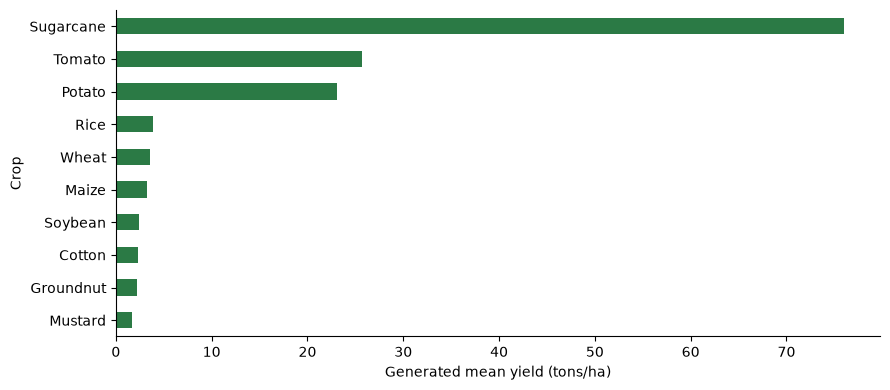

Largest production difference after rounding: 0.005000000000109139
Actual input columns: ['Area_ha', 'Rainfall_mm', 'Temperature_c', 'Fertilizer_kg_ha', 'Crop', 'Season', 'State', 'Irrigation_Type']


In [3]:
df.groupby("Crop")["Yield_tons_per_ha"].mean().sort_values().plot.barh(color="#2b7a45")
plt.xlabel("Generated mean yield (tons/ha)")
plt.tight_layout()
plt.show()
production_error = (df["Production_tons"] - df["Yield_tons_per_ha"] * df["Area_ha"]).abs()
print("Largest production difference after rounding:", production_error.max())
print("Actual input columns:", spec["numeric"] + spec["categorical"])
assert "Production_tons" not in spec["numeric"] + spec["categorical"]

**Read the output:** Production differs from yield × area only by source rounding. It is excluded from X. Large between-crop differences can make aggregate R² look strong even when some per-crop errors matter.

## Features, target and independent split

**What we do:** Select only the declared input columns, then create an 80/20 train/test split.

**Why we do it:** The test labels must not influence fitting, preprocessing or model selection. Classification is stratified to preserve class proportions. Seed 42 makes the split reproducible.

In [4]:
from src.ml import split_data, make_pipeline, train_model, predict, feature_importance
X_train, X_test, y_train, y_test = split_data(KIND, df)
print("Input columns:", X_train.columns.tolist())
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("Index overlap:", len(set(X_train.index) & set(X_test.index)))
display(X_train.head())

Input columns: ['Area_ha', 'Rainfall_mm', 'Temperature_c', 'Fertilizer_kg_ha', 'Crop', 'Season', 'State', 'Irrigation_Type']
Training shape: (2000, 8) Test shape: (500, 8)
Index overlap: 0


,Area_ha,Rainfall_mm,Temperature_c,Fertilizer_kg_ha,Crop,Season,State,Irrigation_Type
2055,20.46,979.8,15.9,180.9,Mustard,Zaid,West Bengal,Drip
1961,28.88,503.6,35.8,186.8,Maize,Rabi,Uttar Pradesh,Tube Well
1864,31.18,457.2,34.8,136.0,Rice,Kharif,Maharashtra,Tube Well
2326,28.67,1262.8,24.9,126.8,Groundnut,Whole Year,Haryana,Sprinkler
461,28.12,464.6,22.3,239.2,Rice,Kharif,West Bengal,Drip


**Read the output:** The overlap should be zero. X contains inputs and y contains the target. Data splitting is performed before fitting the categorical encoder. No scaling is needed for these threshold-based tree models.

## Train and choose a model

**What we do:** Compare a dummy baseline, a Decision Tree and a Random Forest on three training-data folds; fit the best non-dummy candidate and evaluate it on the held-out test set.

**Why we do it:** A baseline gives context. A Decision Tree is easy to explain; a Random Forest combines multiple trees. We choose between the two fitted approaches by validation results rather than assuming one will always win.

In [5]:
# Read src/ml.py for the shared training implementation.
# save=False reproduces results without overwriting the app's saved models.
bundle = train_model(KIND, save=False)
metrics = bundle["metrics"]
display(pd.DataFrame(metrics["comparison"]).round(4))
print("Selection metric:", metrics["cv_metric"])
print("Selected model:", metrics["selected_model"])
display(bundle["pipeline"])

,model,cv_score,cv_std
0,Dummy baseline,13.3833,0.3964
1,Decision Tree,1.7653,0.1054
2,Random Forest,1.3020,0.0864


Selection metric: MAE in tons/ha (lower is better)
Selected model: Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Area_ha','Rainfall_mm','Temperature_c',...,'Season','State', 'Irrigation_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subse

**Read the output:** For classifiers, higher macro F1 is better. For yield regression, lower mean absolute error is better. The dummy baseline predicts the most frequent class or median yield. It is a reference, not a candidate for the final app. Cross-validation scores are separate from the held-out metrics shown next.

## Evaluate regression in meaningful units

**What we do:** Report MAE, RMSE and R²; plot actual versus predicted yield and errors by crop.

**Why we do it:** MAE is the average absolute error in tons/ha. RMSE emphasizes larger errors. R² compares squared error with a constant-mean baseline and can be negative for poor predictions.

MAE: 1.098 tons/ha
RMSE: 2.647 tons/ha
R2: 0.9871


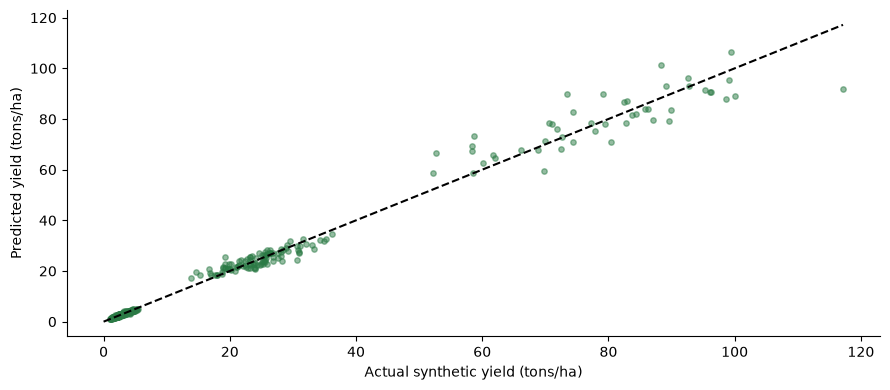

,MAE (tons/ha)
Mustard,0.137002
Cotton,0.164718
Groundnut,0.172379
Soybean,0.204893
Wheat,0.231038
Maize,0.279618
Rice,0.285909
Potato,1.727594
Tomato,1.822847
Sugarcane,6.137698


In [6]:
print(f"MAE: {metrics['mae']:.3f} tons/ha")
print(f"RMSE: {metrics['rmse']:.3f} tons/ha")
print(f"R2: {metrics['r2']:.4f}")
predicted = bundle["pipeline"].predict(X_test)
fig, ax = plt.subplots()
ax.scatter(y_test, predicted, s=15, alpha=0.5, color="#2b7a45")
limit = max(float(y_test.max()), float(predicted.max()))
ax.plot([0, limit], [0, limit], "--", color="black")
ax.set(xlabel="Actual synthetic yield (tons/ha)", ylabel="Predicted yield (tons/ha)")
plt.tight_layout()
plt.show()
display(pd.Series(metrics["mae_by_crop"], name="MAE (tons/ha)").sort_values().to_frame())

**Read the output:** Points near the diagonal are closer predictions. R² is not a percentage accuracy. Review per-crop MAE because an error of one ton/ha means different things for low-yield and high-yield crops.

## Inspect model feature importance

**What we do:** Rank inputs by their contribution to tree impurity reduction.

**Why we do it:** This gives a starting point for discussing what the model uses. It is not a causal explanation and can be misleading for correlated or high-cardinality inputs.

,Feature,Importance
0,category__Crop_Sugarcane,0.819817
1,category__Crop_Tomato,0.070024
2,category__Crop_Potato,0.062345
3,numeric__Fertilizer_kg_ha,0.018280
4,category__Irrigation_Type_Drip,0.006659
5,numeric__Rainfall_mm,0.004441
6,category__Irrigation_Type_Tube Well,0.003694
7,category__Irrigation_Type_Rainfed,0.003686
8,category__Irrigation_Type_Canal,0.002274
9,numeric__Area_ha,0.002039


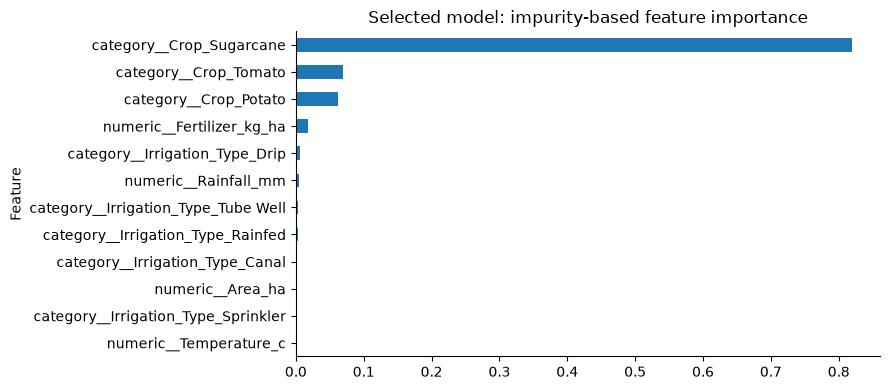

In [7]:
importance = feature_importance(bundle)
display(importance.head(12))
importance.head(12).sort_values("Importance").plot.barh(x="Feature", y="Importance", legend=False)
plt.title("Selected model: impurity-based feature importance")
plt.tight_layout()
plt.show()

**Read the output:** The prefix numeric__ identifies a numerical feature; category__ identifies an encoded category. Importance values are model-specific, not biological rules.

## Predict an example farm's yield

**What we do:** Supply the categorical and numerical features expected by the saved pipeline.

**Why we do it:** Input validation checks categories, positive area, finite numbers and training-range coverage.

In [8]:
example = {"Crop": "Rice", "Season": "Kharif", "State": "Punjab", "Irrigation_Type": "Canal",
           "Area_ha": 2.0, "Rainfall_mm": 800.0, "Temperature_c": 27.0, "Fertilizer_kg_ha": 150.0}
result = predict(KIND, example, bundle)
print(f"Predicted yield: {result['prediction']:.3f} tons/ha")
print("Range warnings:", result["warnings"])

Predicted yield: 4.378 tons/ha
Range warnings: []


**Read the output:** The returned number is yield per hectare, not total production. It is a model estimate with the test-error limitations discussed above.

## Convert units and calculate sample economics

**What we do:** Convert yield to production and quintals/acre, then calculate revenue, cost, profit and margin.

**Why we do it:** Explicit arithmetic makes the financial assumptions auditable. The supplied app uses editable assumptions instead of describing old static prices as current market data.

production_tons             8.756833
yield_quintals_acre        17.718851
revenue                175136.666667
cost                    60000.000000
profit                 115136.666667
margin_pct                 65.741040
Name: Scenario result, dtype: float64

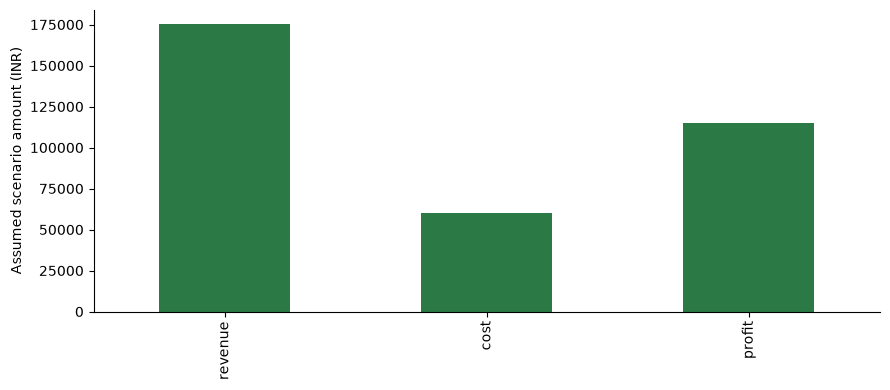

In [9]:
from src.advisory import farm_economics
economics = farm_economics(
    yield_tons_ha=result["prediction"], area_ha=2.0,
    price_per_quintal=2000.0, cost_per_ha=30000.0
)
display(pd.Series(economics, name="Scenario result"))
pd.Series({key: economics[key] for key in ["revenue", "cost", "profit"]}).plot.bar(color="#2b7a45")
plt.ylabel("Assumed scenario amount (INR)")
plt.tight_layout()
plt.show()

**Read the output:** Production = tons/ha × ha. One metric ton is 10 quintals, and one hectare is approximately 2.47105 acres. Revenue = production × 10 × price/quintal. Cost = area × cost/ha. Profit = revenue - cost; margin = profit/revenue × 100. Zero revenue has an undefined margin.

## Run rainfall scenarios

**What we do:** Predict three scenarios while changing only rainfall by -25%, 0% and +25%.

**Why we do it:** This illustrates sensitivity of the fitted model. It does not establish a causal effect or predict weather.

,Scenario,Rainfall (mm),Yield (tons/ha),Outside training range
0,25% less rain,600.0,4.375167,False
1,Entered rainfall,800.0,4.378417,False
2,25% more rain,1000.0,4.344500,False


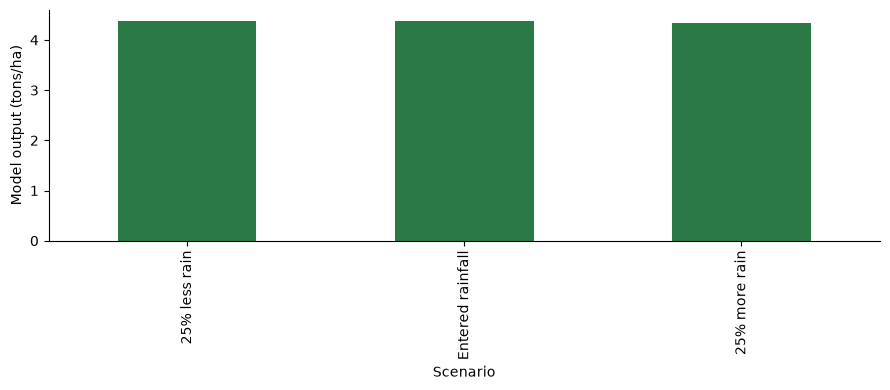

In [10]:
from src.advisory import rainfall_scenarios
scenarios = rainfall_scenarios(example, bundle)
display(scenarios)
scenarios.set_index("Scenario")["Yield (tons/ha)"].plot.bar(color="#2b7a45")
plt.ylabel("Model output (tons/ha)")
plt.tight_layout()
plt.show()

**Read the output:** More rain need not produce more yield in this model. The generated relationship has a preferred rainfall range. The last column flags inputs outside the model's training ranges.

## Application connection
The app accepts hectares or acres, converts to hectares, predicts yield and displays production and
sample economics. Price and cultivation cost are visibly editable. Negative profit is kept as a loss;
it is not clamped to zero. A zero selling price produces an undefined margin rather than a division error.

## Limitations and future work
This dataset has random noise and hand-set yield relationships. Its state/season/temperature fields
do not justify regional predictions. A real extension needs observed yields across multiple seasons
and locations, geographic/time-based holdouts, documented input periods and uncertainty estimates.
Money outputs inherit forecast error and omitted costs as well as the user's assumed prices.

## Viva questions
**Why regression?** Yield is a continuous number.

**Why exclude production?** It is derived directly from the target and area, so using it leaks the answer.

**Why MAE as the selection metric?** It is interpretable in the target unit, tons/ha.

**Why show per-crop errors?** Aggregate metrics can hide scale-related differences.

**Is R² an accuracy percentage?** No. It compares squared prediction error with target variability.

**Exercise:** keep yield fixed, lower the assumed selling price, and find when profit becomes negative.